# 🚦 Traffic Violation Detection System
### Automated Photo & Video Identification using YOLOv8

**Targets:** Red-light violation · Stop-line violation · Wrong-side driving  
**Dataset:** 23-class traffic dataset (5,254 train / 1,470 val images)  
**Model:** YOLOv8m fine-tuned on COCO pretrained weights

---
### 📋 Table of Contents
1. [Setup & Install](#1)
2. [Dataset Preparation & Analysis](#2)
3. [Dataset Labeling Audit](#3)
4. [Model Training](#4)
5. [Model Evaluation (Metrics)](#5)
6. [Inference on Images](#6)
7. [Inference on Video](#7)
8. [Analytics & Reporting](#8)

---
## 1. Setup & Install <a id='1'></a>

In [2]:
# Install all dependencies
!pip install ultralytics opencv-python matplotlib seaborn pandas PyYAML -q
print("✅ Dependencies installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 18.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 80.4 MB/s eta 0:00:00:00:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires n

In [3]:
import os, sys, json, csv, glob, random, shutil, warnings
from pathlib import Path
from datetime import datetime
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import seaborn as sns
import yaml
from IPython.display import display, Image as IPImage, Video, HTML
from ultralytics import YOLO

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

print("✅ All imports successful")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ All imports successful


In [4]:
import torch
print(f"PyTorch  : {torch.__version__}")
print(f"CUDA available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU : {torch.cuda.get_device_name(0)}")
    DEVICE = 0
else:
    print("⚠️  No GPU found — training will be slow on CPU")
    DEVICE = 'cpu'

PyTorch  : 2.10.0+cu128
CUDA available : True
GPU : Tesla T4


---
## 2. Dataset Preparation & Analysis <a id='2'></a>

> **If running on Google Colab:** Upload `archive-2.zip` to your Drive and mount it,  
> or upload directly and unzip below.  
> **If running locally:** Point `DATASET_ROOT` to where you extracted the zip.

In [5]:
# ─── CONFIGURE PATHS ─────────────────────────────────────────────────────────
# Option A: Colab — unzip uploaded file
# !unzip -q archive-2.zip -d ./dataset/

# Option B: Colab — mount Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# !unzip -q /content/drive/MyDrive/archive-2.zip -d ./dataset/

# Option C: Local — just set path
DATASET_ROOT = Path("/kaggle/input/datasets/snehaaa007/traffic/archive-2")   # ← update if needed
OUTPUT_DIR   = Path("./results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset root : {DATASET_ROOT.resolve()}")
print(f"Exists       : {DATASET_ROOT.exists()}")

Dataset root : /kaggle/input/datasets/snehaaa007/traffic/archive-2
Exists       : True


In [6]:
# Write corrected dataset YAML with absolute path
YAML_PATH = Path("traffic_violation.yaml")

dataset_cfg = {
    "path" : str(DATASET_ROOT.resolve()),
    "train": "images/train",
    "val"  : "images/val",
    "nc"   : 23,
    "names": {
        0:"person", 1:"car", 2:"truck", 3:"bus", 4:"motorcycle",
        5:"red light", 6:"green light", 7:"stop sign",
        8:"no entry", 9:"no overtaking",
        10:"speed limit 20", 11:"speed limit 30", 12:"speed limit 40",
        13:"speed limit 50", 14:"speed limit 60", 15:"speed limit 70",
        16:"speed limit 80", 17:"speed limit 100", 18:"speed limit 120",
        19:"no left turn", 20:"no right turn",
        21:"no stopping", 22:"no u-turn"
    }
}

with open(YAML_PATH, 'w') as f:
    yaml.dump(dataset_cfg, f)

# Convenience maps
CLASS_NAMES = dataset_cfg["names"]
VIOLATION_IDS = {5, 7, 8, 9, 19, 20, 21, 22}
VIOLATION_MAP = {
    5:  "RED-LIGHT VIOLATION",
    7:  "STOP-LINE VIOLATION",
    8:  "WRONG-SIDE (no entry)",
    9:  "WRONG-SIDE (no overtaking)",
    19: "ILLEGAL TURN (no left)",
    20: "ILLEGAL TURN (no right)",
    21: "ILLEGAL STOPPING",
    22: "ILLEGAL U-TURN",
}

print(f"✅ YAML written → {YAML_PATH.resolve()}")
print(f"   {len(CLASS_NAMES)} classes | {len(VIOLATION_IDS)} violation classes")

✅ YAML written → /kaggle/working/traffic_violation.yaml
   23 classes | 8 violation classes


In [7]:
# Count files per split
for split in ["train", "val"]:
    imgs = list((DATASET_ROOT / "images" / split).glob("*.jpg"))
    lbls = list((DATASET_ROOT / "labels" / split).glob("*.txt"))
    print(f"{split:5s} → images: {len(imgs):5d}  |  labels: {len(lbls):5d}")

train → images:  5254  |  labels:  5254
val   → images:  1470  |  labels:  1470


---
## 3. Dataset Labeling Audit <a id='3'></a>
Counts instances per class, checks for missing/empty labels, and visualises sample annotations.

In [8]:
def count_classes(split):
    counts = Counter()
    for lf in (DATASET_ROOT / "labels" / split).glob("*.txt"):
        for line in lf.read_text().splitlines():
            parts = line.strip().split()
            if parts: counts[int(parts[0])] += 1
    return counts

train_counts = count_classes("train")
val_counts   = count_classes("val")

# Print table
TARGET = {5, 7, 8, 9}
print(f"{'ID':>3}  {'Class':<22} {'Train':>7}  {'Val':>7}  {'Note'}")
print("-" * 60)
for cid in sorted(CLASS_NAMES.keys()):
    tag = " ◀ TARGET" if cid in TARGET else ""
    print(f"{cid:3d}  {CLASS_NAMES[cid]:<22} {train_counts.get(cid,0):7d}  {val_counts.get(cid,0):7d}{tag}")

 ID  Class                    Train      Val  Note
------------------------------------------------------------
  0  person                     137       50
  1  car                        200      172
  2  truck                      200      167
  3  bus                        200       95
  4  motorcycle                  57       50
  5  red light                  395       80 ◀ TARGET
  6  green light                410       80
  7  stop sign                  335       80 ◀ TARGET
  8  no entry                   169       60 ◀ TARGET
  9  no overtaking              183       26 ◀ TARGET
 10  speed limit 20             331       56
 11  speed limit 30             360       74
 12  speed limit 40             288       55
 13  speed limit 50             333       71
 14  speed limit 60             345       76
 15  speed limit 70             353       78
 16  speed limit 80             361       56
 17  speed limit 100            313       52
 18  speed limit 120            296       

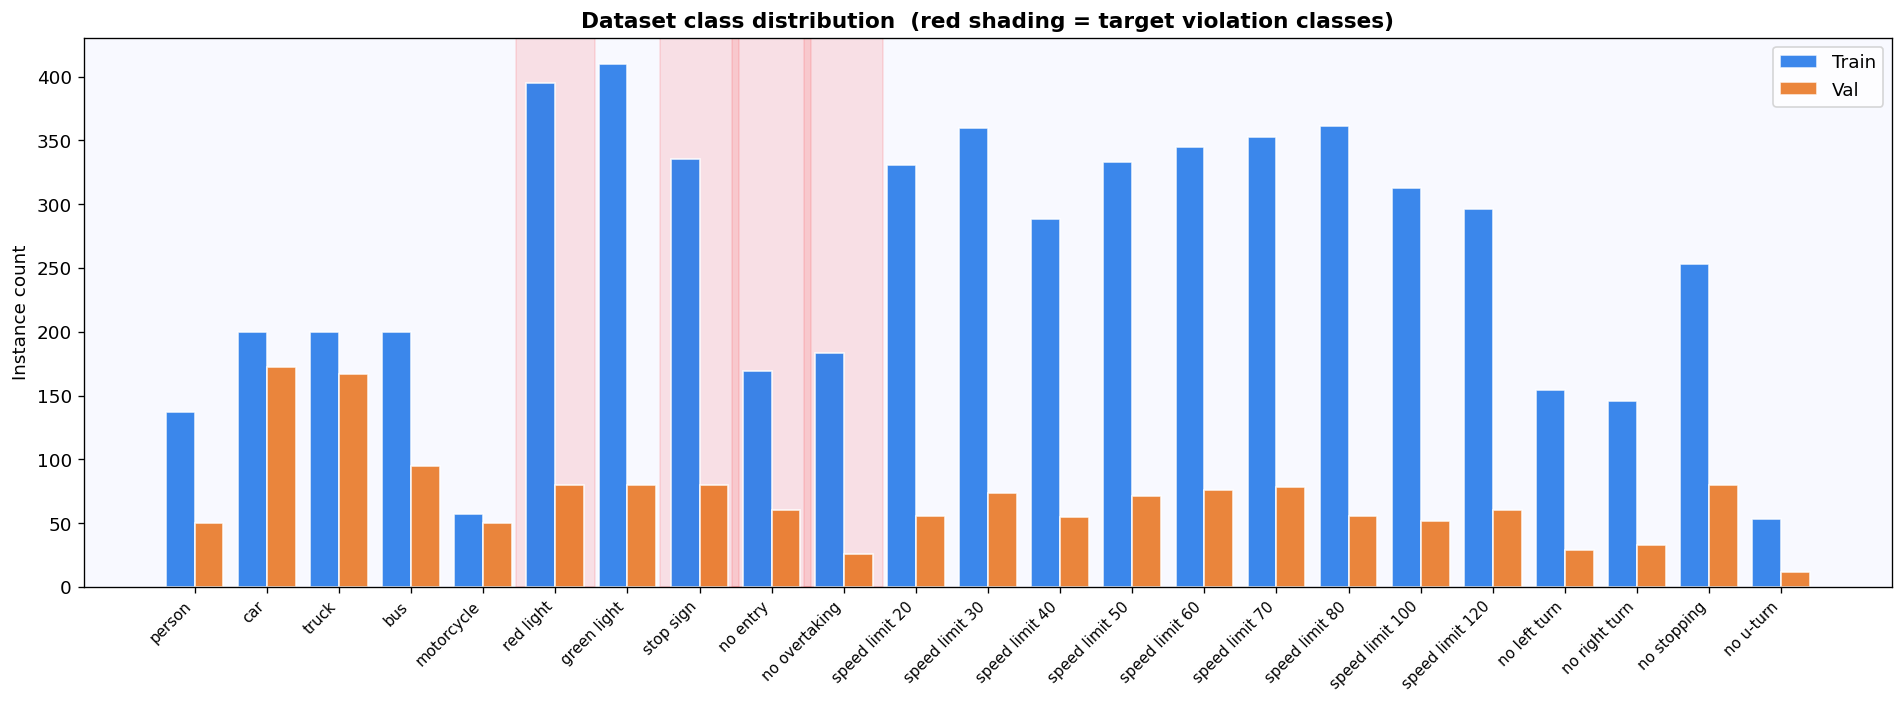

Saved → results/class_distribution.png


In [9]:
# Class distribution bar chart
all_ids = sorted(CLASS_NAMES.keys())
names   = [CLASS_NAMES[c] for c in all_ids]
train_v = [train_counts.get(c, 0) for c in all_ids]
val_v   = [val_counts.get(c, 0)   for c in all_ids]
x = np.arange(len(all_ids))
w = 0.4

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(x - w/2, train_v, w, label="Train", color="#1a73e8", alpha=0.85, edgecolor="white")
ax.bar(x + w/2, val_v,   w, label="Val",   color="#e8711a", alpha=0.85, edgecolor="white")

for i, cid in enumerate(all_ids):
    if cid in TARGET:
        ax.axvspan(i - 0.55, i + 0.55, alpha=0.1, color="red", zorder=0)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Instance count")
ax.set_title("Dataset class distribution  (red shading = target violation classes)", fontsize=13, fontweight="bold")
ax.legend()
ax.set_facecolor("#f8f9ff")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → results/class_distribution.png")

In [10]:
# Adequacy assessment for the 3 target violations
THRESHOLDS = {"good": 300, "adequate": 100, "sparse": 50}
TARGET_VIOLATIONS = {
    5: "RED-LIGHT VIOLATION",
    7: "STOP-LINE VIOLATION",
    8: "WRONG-SIDE (no entry)",
    9: "WRONG-SIDE (no overtaking)",
}
print("\n" + "="*60)
print("  DATASET ADEQUACY FOR TARGET VIOLATIONS")
print("="*60)
for cid, vname in TARGET_VIOLATIONS.items():
    n = train_counts.get(cid, 0)
    if   n >= THRESHOLDS["good"]    : status = "✅ GOOD"
    elif n >= THRESHOLDS["adequate"]: status = "⚠️  ADEQUATE"
    elif n >= THRESHOLDS["sparse"]  : status = "⚠️  SPARSE — consider more data"
    else                            : status = "❌ INSUFFICIENT"
    print(f"  Class {cid:2d}  {vname:<30}  {n:4d} instances  →  {status}")
print("="*60)


  DATASET ADEQUACY FOR TARGET VIOLATIONS
  Class  5  RED-LIGHT VIOLATION              395 instances  →  ✅ GOOD
  Class  7  STOP-LINE VIOLATION              335 instances  →  ✅ GOOD
  Class  8  WRONG-SIDE (no entry)            169 instances  →  ⚠️  ADEQUATE
  Class  9  WRONG-SIDE (no overtaking)       183 instances  →  ⚠️  ADEQUATE


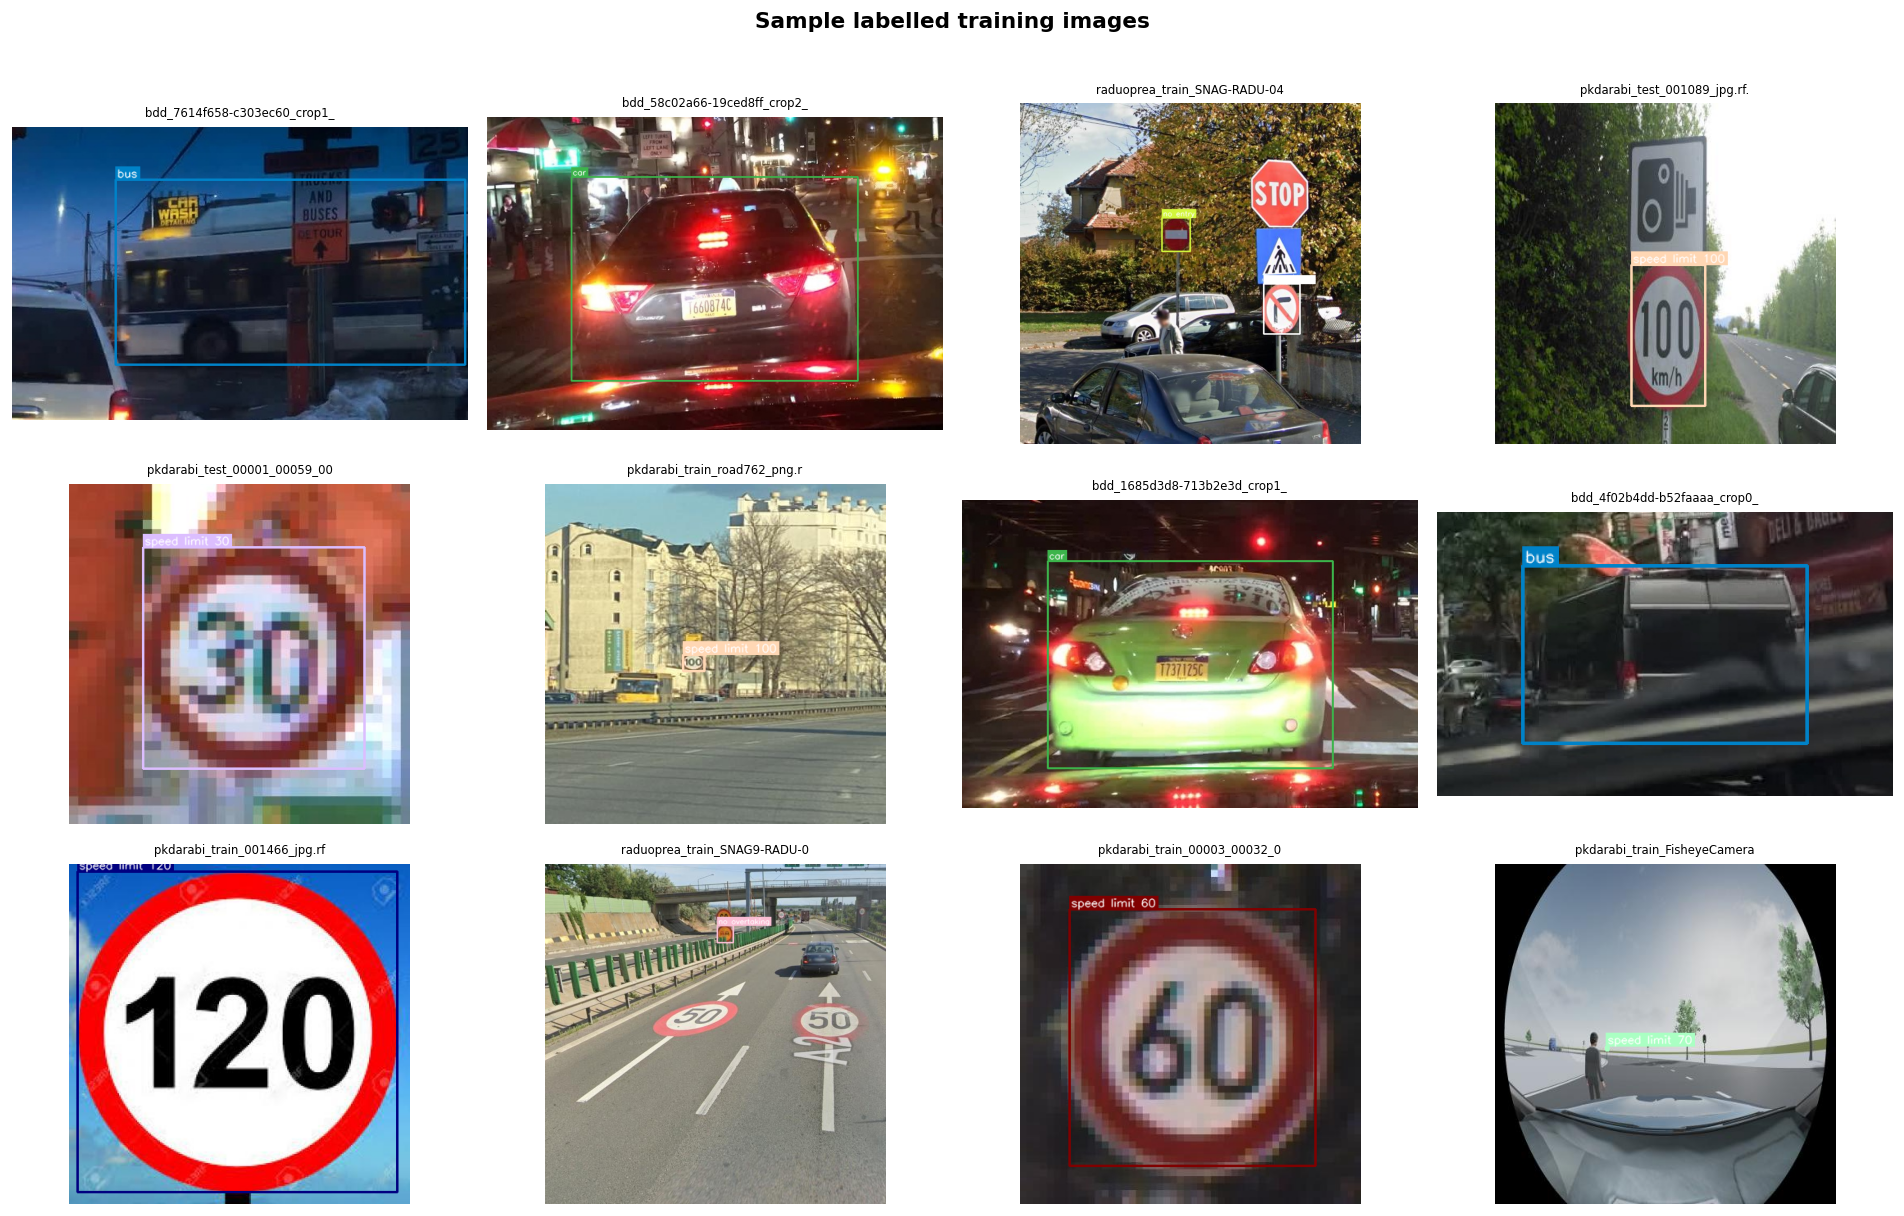

In [11]:
# Visualise 12 labelled training samples
BOX_COLORS = [
    (230,25,75),(60,180,75),(255,225,25),(0,130,200),(245,130,48),
    (145,30,180),(70,240,240),(240,50,230),(210,245,60),(250,190,212),
    (0,128,128),(220,190,255),(170,110,40),(255,250,200),(128,0,0),
    (170,255,195),(128,128,0),(255,215,180),(0,0,128),(128,128,128),
    (255,255,255),(0,0,0),(200,80,80)
]

def draw_yolo_boxes(img, label_path):
    out = img.copy()
    h, w = out.shape[:2]
    if not Path(label_path).exists(): return out
    for line in Path(label_path).read_text().splitlines():
        p = line.strip().split()
        if len(p) < 5: continue
        cid = int(p[0])
        cx,cy,bw,bh = float(p[1]),float(p[2]),float(p[3]),float(p[4])
        x1,y1 = int((cx-bw/2)*w), int((cy-bh/2)*h)
        x2,y2 = int((cx+bw/2)*w), int((cy+bh/2)*h)
        c = BOX_COLORS[cid % len(BOX_COLORS)]
        bgr = (c[2],c[1],c[0])
        cv2.rectangle(out,(x1,y1),(x2,y2),bgr,2)
        lbl = CLASS_NAMES.get(cid, str(cid))
        (tw,th),_ = cv2.getTextSize(lbl, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
        cv2.rectangle(out,(x1,y1-th-6),(x1+tw+4,y1),bgr,-1)
        cv2.putText(out,lbl,(x1+2,y1-3),cv2.FONT_HERSHEY_SIMPLEX,0.45,(255,255,255),1,cv2.LINE_AA)
    return out

img_paths = random.sample(list((DATASET_ROOT/"images"/"train").glob("*.jpg")), 12)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, ip in zip(axes.flatten(), img_paths):
    img = cv2.imread(str(ip))
    lp  = DATASET_ROOT / "labels" / "train" / (ip.stem + ".txt")
    ann = draw_yolo_boxes(img, lp)
    ax.imshow(cv2.cvtColor(ann, cv2.COLOR_BGR2RGB))
    ax.set_title(ip.name[:28], fontsize=7)
    ax.axis("off")
plt.suptitle("Sample labelled training images", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_grid_train.png", dpi=120, bbox_inches="tight")
plt.show()

---
## 4. Model Training <a id='4'></a>

Fine-tunes **YOLOv8m** on the traffic violation dataset.  
Change `MODEL_SIZE` to `yolov8s` for a faster (less accurate) run.

In [12]:
# ─── TRAINING CONFIG ─────────────────────────────────────────────────────────
MODEL_SIZE  = "yolov8m"   # yolov8n | yolov8s | yolov8m | yolov8l
EPOCHS      = 100
IMG_SIZE    = 640
BATCH_SIZE  = 16          # lower to 8 if OOM
PROJECT     = "runs/train"
RUN_NAME    = "traffic_violation_exp1"

model = YOLO(f"{MODEL_SIZE}.pt")  # loads COCO pretrained weights

results = model.train(
    data        = str(YAML_PATH),
    epochs      = EPOCHS,
    imgsz       = IMG_SIZE,
    batch       = BATCH_SIZE,
    device      = DEVICE,
    project     = PROJECT,
    name        = RUN_NAME,
    # ── augmentation for robustness (night / rain / blur) ──
    hsv_h       = 0.015,
    hsv_s       = 0.7,
    hsv_v       = 0.4,
    degrees     = 5.0,
    translate   = 0.1,
    scale       = 0.5,
    shear       = 2.0,
    perspective = 0.0001,
    flipud      = 0.0,
    fliplr      = 0.5,
    mosaic      = 1.0,
    mixup       = 0.1,
    # ── optimizer ──────────────────────────────────────────
    optimizer   = "AdamW",
    lr0         = 0.001,
    lrf         = 0.01,
    warmup_epochs = 3,
    patience    = 20,
    save_period = 10,
    plots       = True,
    exist_ok    = True,
)

BEST_MODEL = Path(PROJECT) / RUN_NAME / "weights" / "best.pt"
print(f"\n✅ Training complete!")
print(f"   Best weights → {BEST_MODEL.resolve()}")

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=traffic_violation.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=traffic_violation_exp1, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, pati

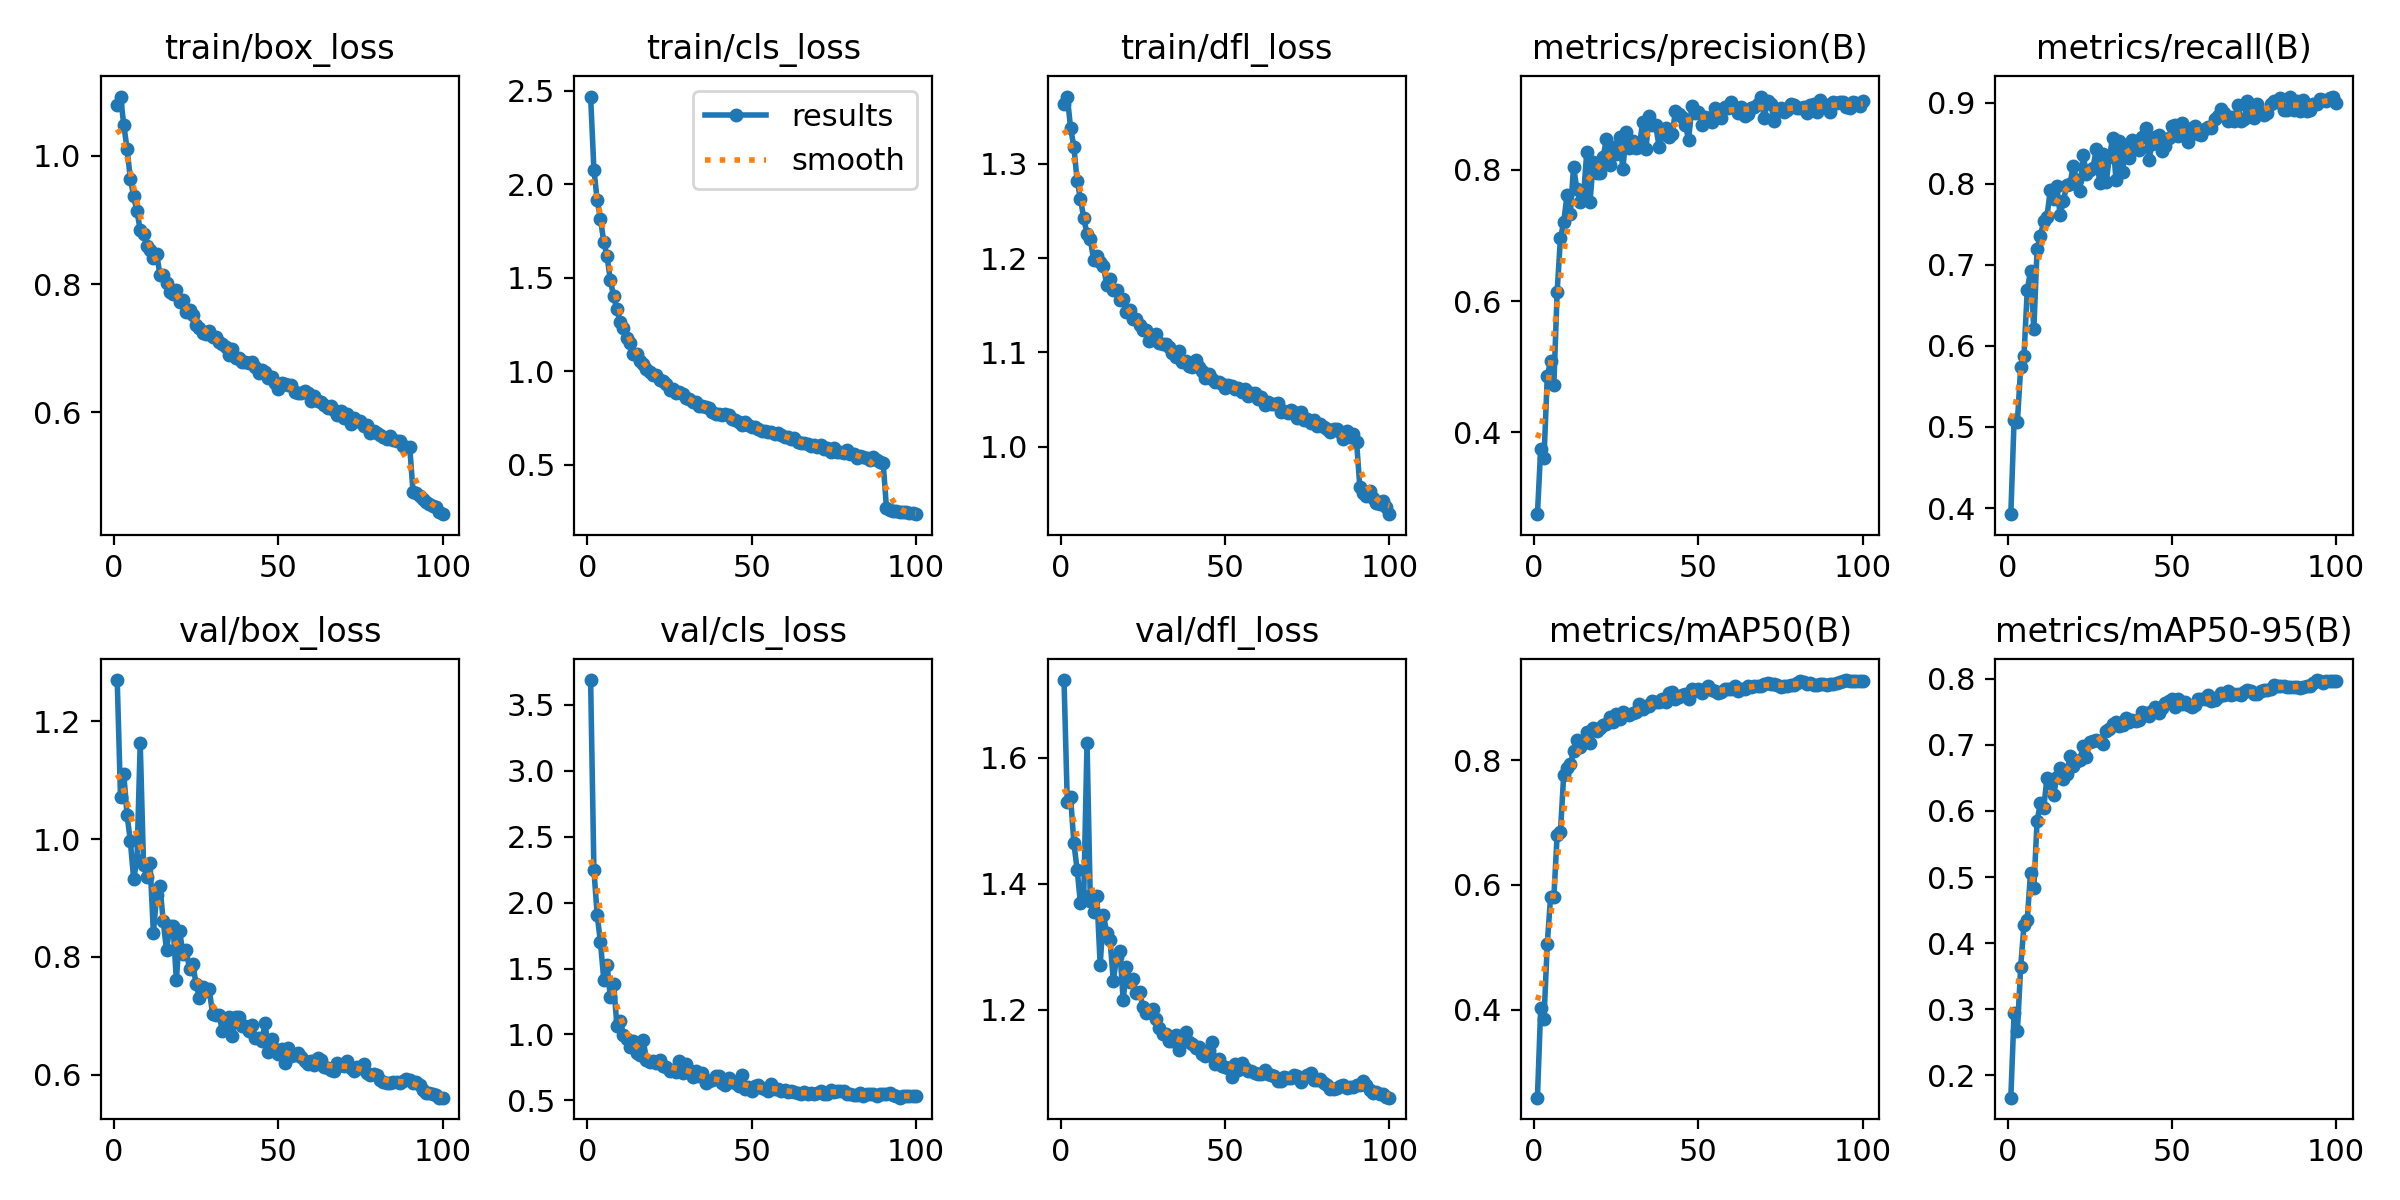

In [19]:
from pathlib import Path

results_png = Path("/kaggle/working/runs/detect/runs/train/traffic_violation_exp1/results.png")
if results_png.exists():
    display(IPImage(str(results_png), width=900))
else:
    print("results.png not found — check training completed without errors")

---
## 5. Model Evaluation <a id='5'></a>
Runs validation and reports **Precision, Recall, F1, mAP@50, mAP@50-95** per class.

In [21]:
# Load best model (or set a custom path here)
BEST_MODEL = Path("/kaggle/working/runs/detect/runs/train/traffic_violation_exp1/weights/best.pt")  # ← uncomment to use existing weights

eval_model = YOLO(str(BEST_MODEL))
val_results = eval_model.val(
    data     = str(YAML_PATH),
    imgsz    = IMG_SIZE,
    batch    = 16,
    verbose  = True,
    plots    = True,
    project  = str(OUTPUT_DIR),
    name     = "val_metrics",
    exist_ok = True,
)

mp  = val_results.box.mp
mr  = val_results.box.mr
mf1 = 2*mp*mr / (mp+mr+1e-9)

print("\n" + "="*50)
print("  OVERALL METRICS")
print("="*50)
print(f"  mAP@50    : {val_results.box.map50:.4f}")
print(f"  mAP@50-95 : {val_results.box.map:.4f}")
print(f"  Precision : {mp:.4f}")
print(f"  Recall    : {mr:.4f}")
print(f"  F1 score  : {mf1:.4f}")
print("="*50)

Ultralytics 8.4.71 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 93 layers, 25,853,077 parameters, 0 gradients, 78.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 29.1±14.4 MB/s, size: 14.9 KB)
val: Scanning /kaggle/input/datasets/snehaaa007/traffic/archive-2/labels/val... 1470 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1470/1470 963.7it/s 1.5s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/snehaaa007/traffic/archive-2/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 92/92 2.1it/s 44.5s0.3ss
                   all       1470       1592      0.909      0.894      0.927      0.797
                person         50         50      0.932      0.821      0.915        0.8
                   car        172        172      0.837      0.684      0.819      0.688
                 truck        167        167      0.651      0.

In [22]:
# Per-class mAP table
maps = val_results.box.maps
rows = []
for cid, cname in val_results.names.items():
    map_val = maps[cid] if cid < len(maps) else float('nan')
    rows.append({
        "Class ID"  : cid,
        "Class"     : cname,
        "mAP@50"    : round(float(map_val), 4),
        "Violation?": "⚠ YES" if cid in VIOLATION_IDS else ""
    })

df_metrics = pd.DataFrame(rows)
df_metrics = df_metrics.sort_values("mAP@50", ascending=False)
display(df_metrics.style
    .background_gradient(subset=["mAP@50"], cmap="RdYlGn")
    .set_caption("Per-class mAP@50")
    .hide(axis="index")
)
df_metrics.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)
print("Saved → results/per_class_metrics.csv")

Class ID,Class,mAP@50,Violation?
7,stop sign,0.929200,⚠ YES
11,speed limit 30,0.913500,
18,speed limit 120,0.913300,
15,speed limit 70,0.892900,
17,speed limit 100,0.889600,
14,speed limit 60,0.888000,
13,speed limit 50,0.879400,
16,speed limit 80,0.872200,
20,no right turn,0.870400,⚠ YES
10,speed limit 20,0.856000,


Saved → results/per_class_metrics.csv


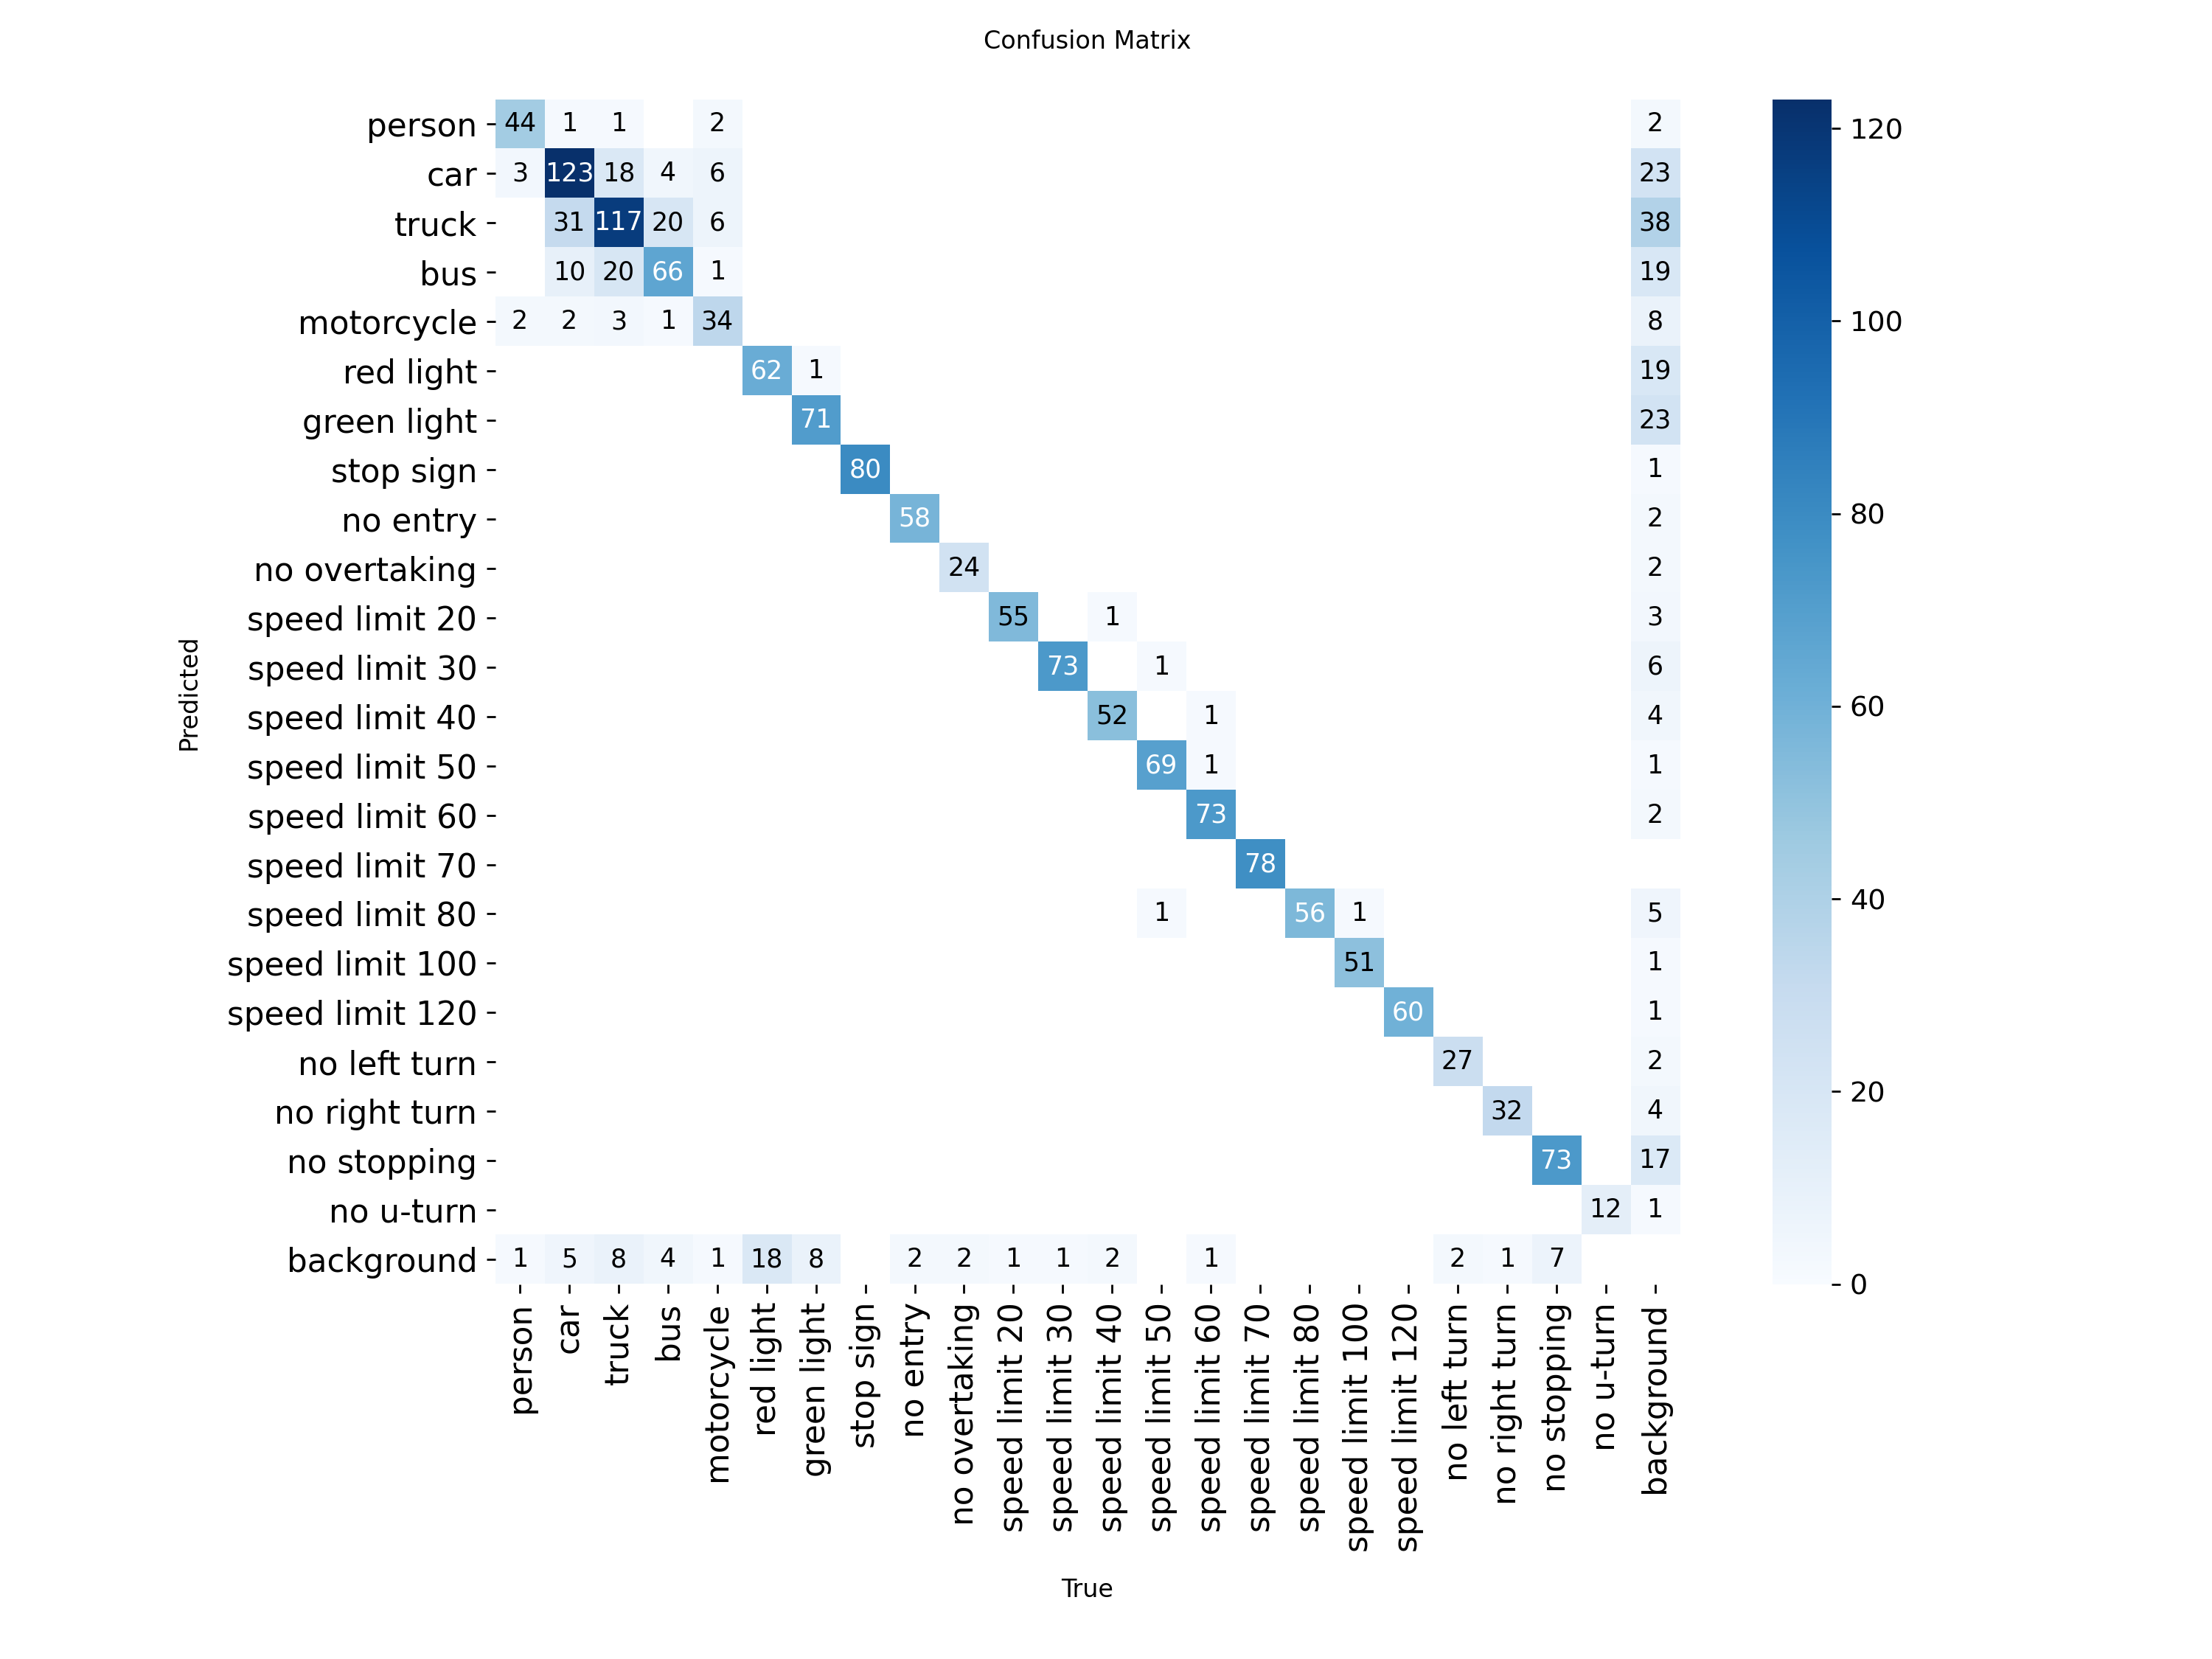

In [23]:
# Display confusion matrix (saved by Ultralytics during val)
cm_path = OUTPUT_DIR / "val_metrics" / "confusion_matrix.png"
if cm_path.exists():
    display(IPImage(str(cm_path), width=700))
else:
    # Alternative: search wherever Ultralytics saved it
    candidates = list(Path(".").rglob("confusion_matrix.png"))
    if candidates:
        display(IPImage(str(candidates[0]), width=700))
    else:
        print("Confusion matrix not found — check val output directory")

---
## 6. Inference on Images <a id='6'></a>

In [24]:
# ─── Colour scheme for annotation boxes ──────────────────────────────────────
VIOL_COLORS = {
    5:  (0, 0, 230),      # red light      → RED
    7:  (0, 140, 255),    # stop sign      → ORANGE
    8:  (0, 0, 180),      # no entry       → DARK RED
    9:  (128, 0, 128),    # no overtaking  → PURPLE
    19: (147, 20, 255),
    20: (147, 20, 255),
    21: (60, 20, 220),
    22: (0, 69, 255),
}
VEH_COLOR  = (30, 180, 30)   # green  for vehicles
SIGN_COLOR = (0, 165, 255)   # orange for other signs

def get_color(cid):
    if cid in VIOL_COLORS: return VIOL_COLORS[cid]
    if cid in {0,1,2,3,4}: return VEH_COLOR
    return SIGN_COLOR

def annotate_frame(frame, boxes, confs, cls_ids):
    img = frame.copy()
    h, w = img.shape[:2]
    violations = []
    for box, conf, cid in zip(boxes, confs, cls_ids):
        cid = int(cid)
        x1,y1,x2,y2 = [int(v) for v in box]
        color = get_color(cid)
        viol  = VIOLATION_MAP.get(cid)
        if viol: violations.append(viol)
        lbl   = f"{'⚠ ' if viol else ''}{CLASS_NAMES.get(cid,cid)} {conf:.2f}"
        thick = 3 if viol else 2
        cv2.rectangle(img,(x1,y1),(x2,y2),color,thick)
        (tw,th),_ = cv2.getTextSize(lbl,cv2.FONT_HERSHEY_SIMPLEX,0.55,1)
        cv2.rectangle(img,(x1,y1-th-6),(x1+tw+4,y1),color,-1)
        cv2.putText(img,lbl,(x1+2,y1-3),cv2.FONT_HERSHEY_SIMPLEX,0.55,(255,255,255),1,cv2.LINE_AA)
    # Violation banner
    if violations:
        cv2.rectangle(img,(0,0),(w,36),(0,0,180),-1)
        txt = "⚠  VIOLATION: " + "  |  ".join(set(violations))
        cv2.putText(img,txt,(10,24),cv2.FONT_HERSHEY_SIMPLEX,0.62,(255,255,255),2,cv2.LINE_AA)
    return img, violations

print("✅ Annotation helpers defined")

✅ Annotation helpers defined


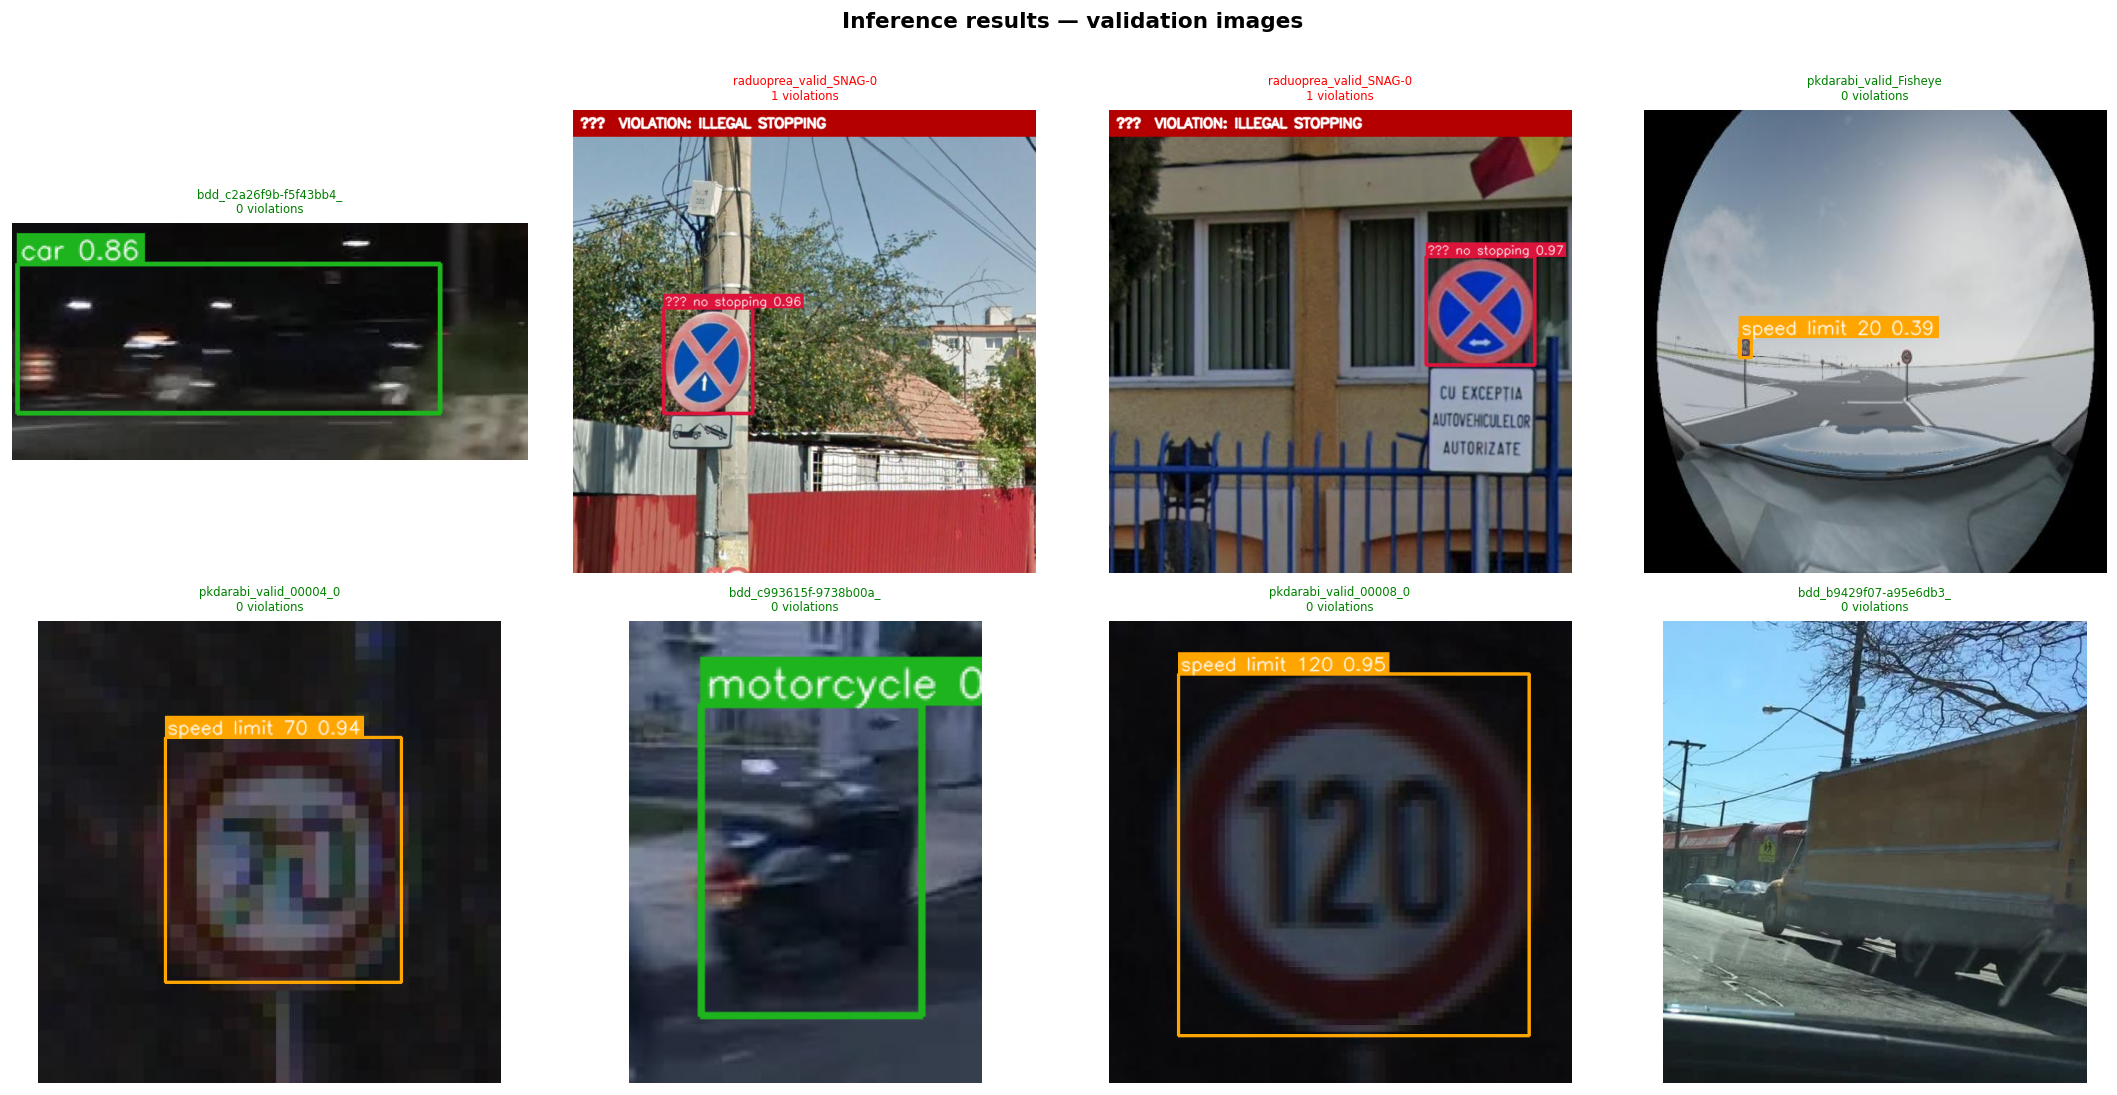

Saved 8 records → results/violation_metadata.json


In [25]:
# Run inference on 8 validation images and display annotated results
inf_model  = YOLO(str(BEST_MODEL))
CONF_THRESH = 0.35

val_imgs   = random.sample(list((DATASET_ROOT/"images"/"val").glob("*.jpg")), 8)
metadata   = []

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, ip in zip(axes.flatten(), val_imgs):
    frame = cv2.imread(str(ip))
    pred  = inf_model(ip, conf=CONF_THRESH, verbose=False)[0]
    boxes   = pred.boxes.xyxy.cpu().numpy()
    confs_a = pred.boxes.conf.cpu().numpy()
    cls_ids = pred.boxes.cls.cpu().numpy()

    ann, viols = annotate_frame(frame, boxes, confs_a, cls_ids)
    ax.imshow(cv2.cvtColor(ann, cv2.COLOR_BGR2RGB))
    title_col = "red" if viols else "green"
    ax.set_title(f"{ip.name[:22]}\n{len(viols)} violations", fontsize=7, color=title_col)
    ax.axis("off")

    metadata.append({
        "image"    : ip.name,
        "timestamp": datetime.now().isoformat(),
        "n_detections": len(boxes),
        "violations"  : viols,
    })

plt.suptitle("Inference results — validation images", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "inference_samples.png", dpi=130, bbox_inches="tight")
plt.show()

# Save metadata
with open(OUTPUT_DIR / "violation_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(f"Saved {len(metadata)} records → results/violation_metadata.json")

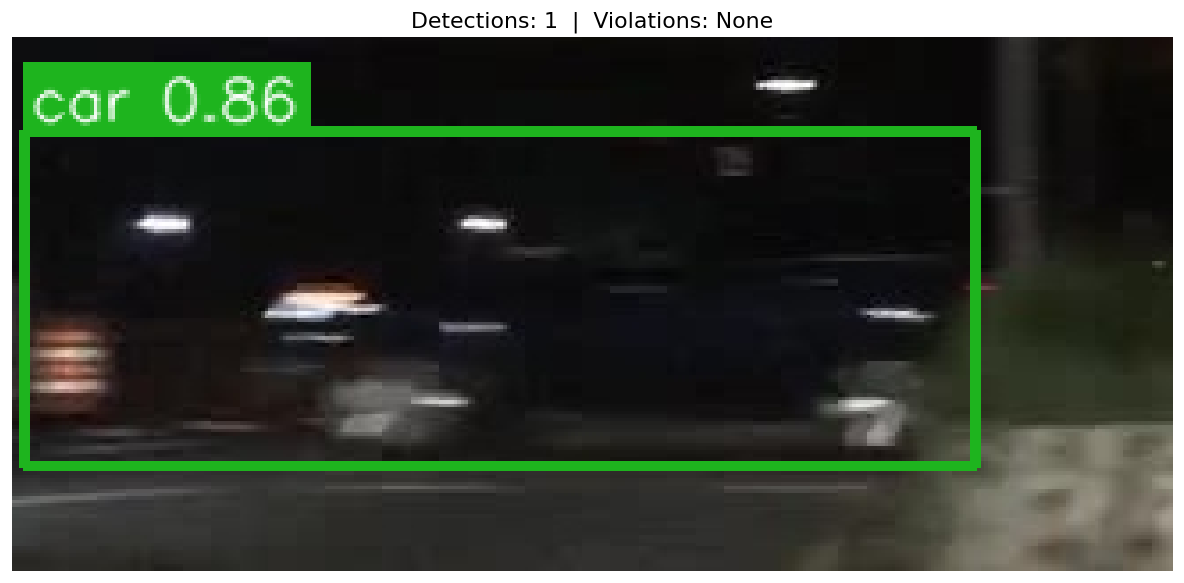

In [26]:
# ── Run on a custom image path ───────────────────────────────────────────────
# Change this path to any image you want to test
CUSTOM_IMAGE = str(val_imgs[0])   # ← replace with your image path

frame = cv2.imread(CUSTOM_IMAGE)
pred  = inf_model(CUSTOM_IMAGE, conf=CONF_THRESH, verbose=False)[0]
boxes   = pred.boxes.xyxy.cpu().numpy()
confs_a = pred.boxes.conf.cpu().numpy()
cls_ids = pred.boxes.cls.cpu().numpy()

ann, viols = annotate_frame(frame, boxes, confs_a, cls_ids)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(ann, cv2.COLOR_BGR2RGB))
plt.title(f"Detections: {len(boxes)}  |  Violations: {viols if viols else 'None'}")
plt.axis("off")
plt.tight_layout()
plt.show()

---
## 7. Inference on Video <a id='7'></a>

Processes the uploaded traffic video frame-by-frame and saves an annotated MP4.

In [28]:
# ─── VIDEO CONFIG ────────────────────────────────────────────────────────────
# Colab: upload the video first, then set path
# from google.colab import files
# uploaded = files.upload()   # select traffic_video_original.mp4

VIDEO_IN  = "/kaggle/input/datasets/snehaaa007/videoo/traffic_video_original.mp4"   # ← update path if needed
VIDEO_OUT = str(OUTPUT_DIR / "traffic_video_annotated.mp4")
CONF_VIDEO = 0.35

if not Path(VIDEO_IN).exists():
    print(f"⚠️  Video not found at: {VIDEO_IN}")
    print("   Set VIDEO_IN to the correct path and re-run")
else:
    cap    = cv2.VideoCapture(VIDEO_IN)
    fps    = int(cap.get(cv2.CAP_PROP_FPS)) or 25
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(VIDEO_OUT, fourcc, fps, (width, height))

    print(f"Input  : {VIDEO_IN}  ({width}×{height} @ {fps}fps, {total} frames)")
    print(f"Output : {VIDEO_OUT}")

    violation_log = []
    frame_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret: break

        pred    = inf_model(frame, conf=CONF_VIDEO, verbose=False)[0]
        boxes   = pred.boxes.xyxy.cpu().numpy()
        confs_a = pred.boxes.conf.cpu().numpy()
        cls_ids = pred.boxes.cls.cpu().numpy()

        ann, viols = annotate_frame(frame, boxes, confs_a, cls_ids)

        # Timestamp overlay
        ts_sec = frame_idx / fps
        cv2.putText(ann, f"{ts_sec:.1f}s", (width-80, height-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200,200,200), 1, cv2.LINE_AA)
        writer.write(ann)

        if viols:
            violation_log.append({"frame": frame_idx, "time_sec": round(ts_sec,2), "violations": viols})

        frame_idx += 1
        if frame_idx % 50 == 0:
            pct = 100*frame_idx/max(total,1)
            print(f"  [{pct:5.1f}%] frame {frame_idx}/{total}", end="\r")

    cap.release()
    writer.release()

    with open(OUTPUT_DIR / "video_violation_log.json", "w") as f:
        json.dump(violation_log, f, indent=2)

    print(f"\n\n✅ Video processed: {frame_idx} frames")
    print(f"   Violation events : {len(violation_log)}")
    print(f"   Annotated video  → {VIDEO_OUT}")
    print(f"   Violation log    → results/video_violation_log.json")

Input  : /kaggle/input/datasets/snehaaa007/videoo/traffic_video_original.mp4  (1920×1012 @ 26fps, 715 frames)
Output : results/traffic_video_annotated.mp4
  [ 97.9%] frame 700/715

✅ Video processed: 715 frames
   Violation events : 12
   Annotated video  → results/traffic_video_annotated.mp4
   Violation log    → results/video_violation_log.json


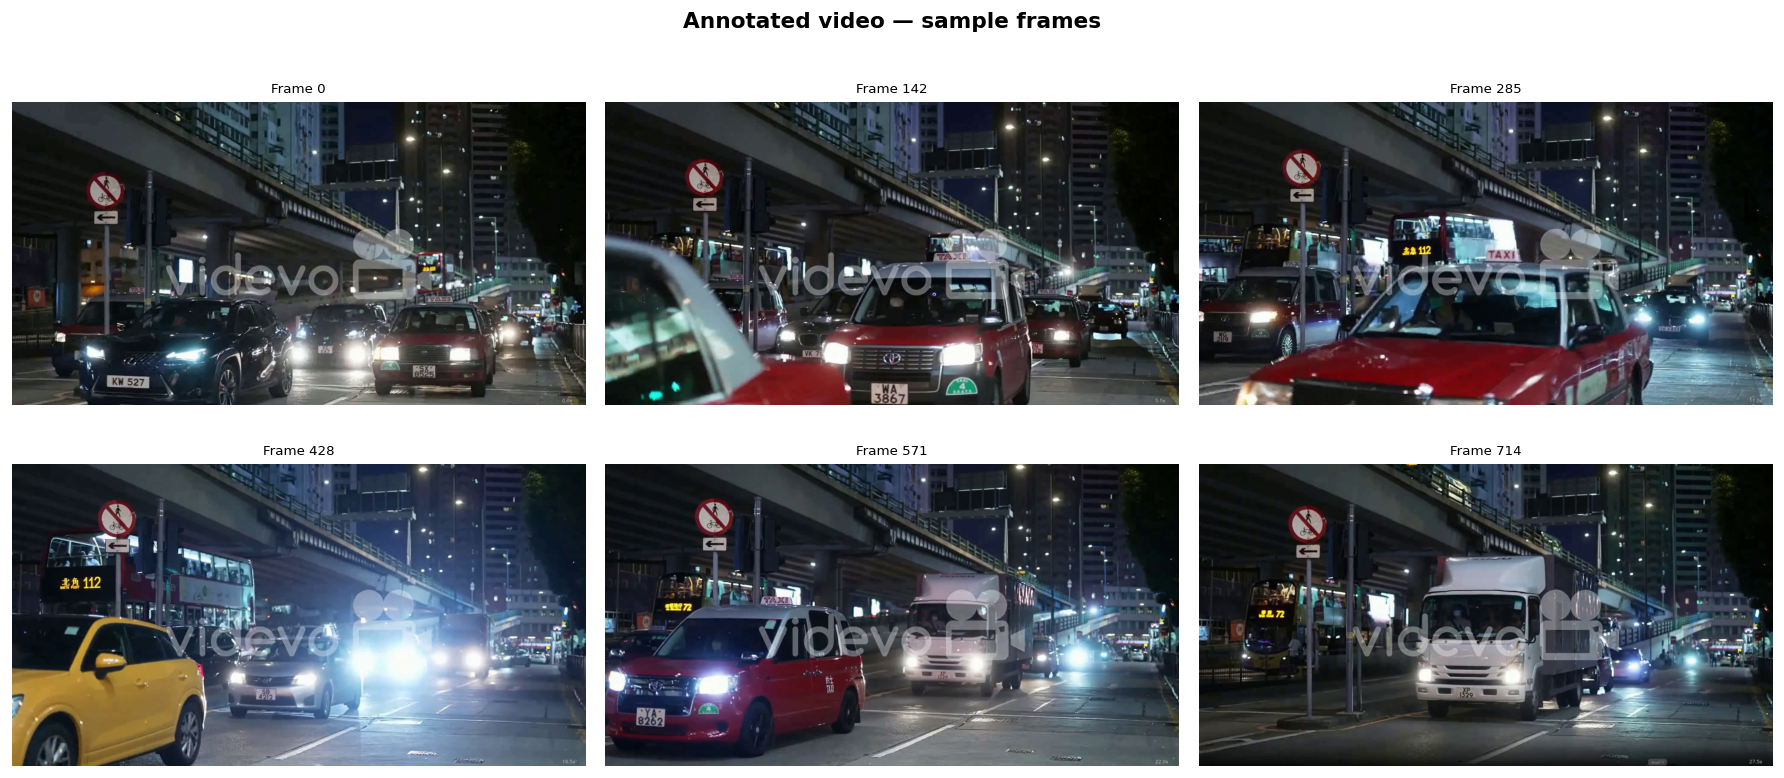

In [30]:
# Preview: pull 6 frames from the annotated video
if Path(VIDEO_OUT).exists():
    cap2 = cv2.VideoCapture(VIDEO_OUT)
    total2 = int(cap2.get(cv2.CAP_PROP_FRAME_COUNT))
    sample_frames_idx = np.linspace(0, total2-1, 6, dtype=int)

    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, fidx in zip(axes.flatten(), sample_frames_idx):
        cap2.set(cv2.CAP_PROP_POS_FRAMES, int(fidx))
        ret, fr = cap2.read()
        if ret:
            ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
            ax.set_title(f"Frame {fidx}", fontsize=8)
        ax.axis("off")
    cap2.release()
    plt.suptitle("Annotated video — sample frames", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Run the video inference cell first.")

---
## 8. Analytics & Reporting <a id='8'></a>

In [31]:
# Load whichever log exists (video preferred, else image metadata)
video_log_path = OUTPUT_DIR / "video_violation_log.json"
image_log_path = OUTPUT_DIR / "violation_metadata.json"

if video_log_path.exists():
    with open(video_log_path) as f: raw = json.load(f)
    rows = [{"time_sec": e["time_sec"], "violation": v}
            for e in raw for v in e["violations"]]
    df_viols = pd.DataFrame(rows)
    print(f"Loaded video log: {len(df_viols)} violation events")
elif image_log_path.exists():
    with open(image_log_path) as f: raw = json.load(f)
    rows = [{"image": e["image"], "violation": v}
            for e in raw for v in e["violations"]]
    df_viols = pd.DataFrame(rows)
    print(f"Loaded image log: {len(df_viols)} violation events")
else:
    print("No log found — run inference sections first")
    df_viols = pd.DataFrame(columns=["violation"])

display(df_viols.head(10))

Loaded video log: 12 violation events


,time_sec,violation
0,9.12,ILLEGAL TURN (no right)
1,9.15,ILLEGAL TURN (no right)
2,9.19,ILLEGAL TURN (no right)
3,9.23,ILLEGAL TURN (no right)
4,9.27,ILLEGAL TURN (no right)
5,14.54,WRONG-SIDE (no entry)
6,14.69,WRONG-SIDE (no entry)
7,14.73,WRONG-SIDE (no entry)
8,14.77,WRONG-SIDE (no entry)
9,14.81,WRONG-SIDE (no entry)


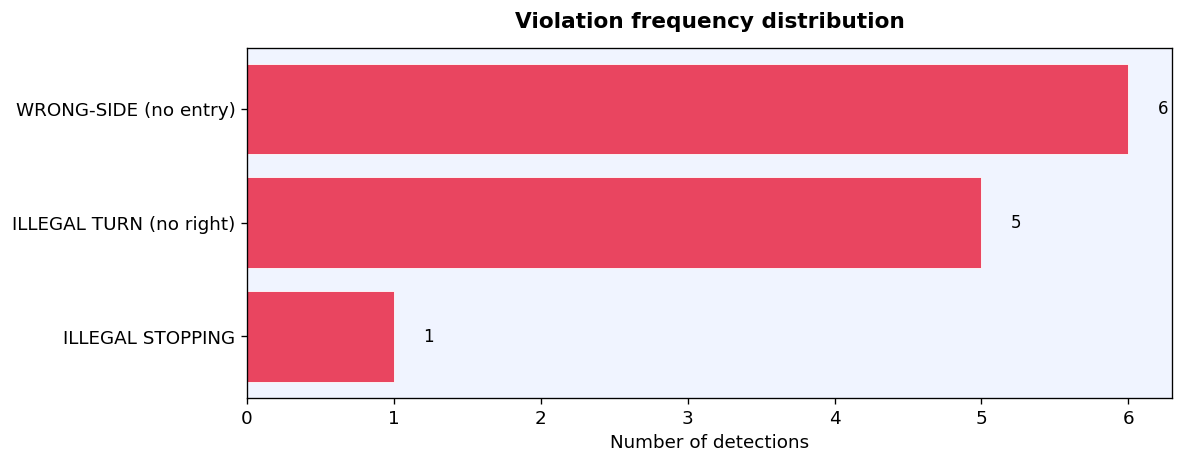

In [32]:
if df_viols.empty or "violation" not in df_viols.columns:
    print("No violations to plot.")
else:
    counts = df_viols["violation"].value_counts()

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.barh(counts.index, counts.values, color="#e94560", edgecolor="white", linewidth=0.5)
    for bar, val in zip(bars, counts.values):
        ax.text(val+0.2, bar.get_y()+bar.get_height()/2, str(val), va="center", fontsize=10)
    ax.set_title("Violation frequency distribution", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Number of detections")
    ax.invert_yaxis()
    ax.set_facecolor("#f0f4ff")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "violation_frequency.png", dpi=150, bbox_inches="tight")
    plt.show()

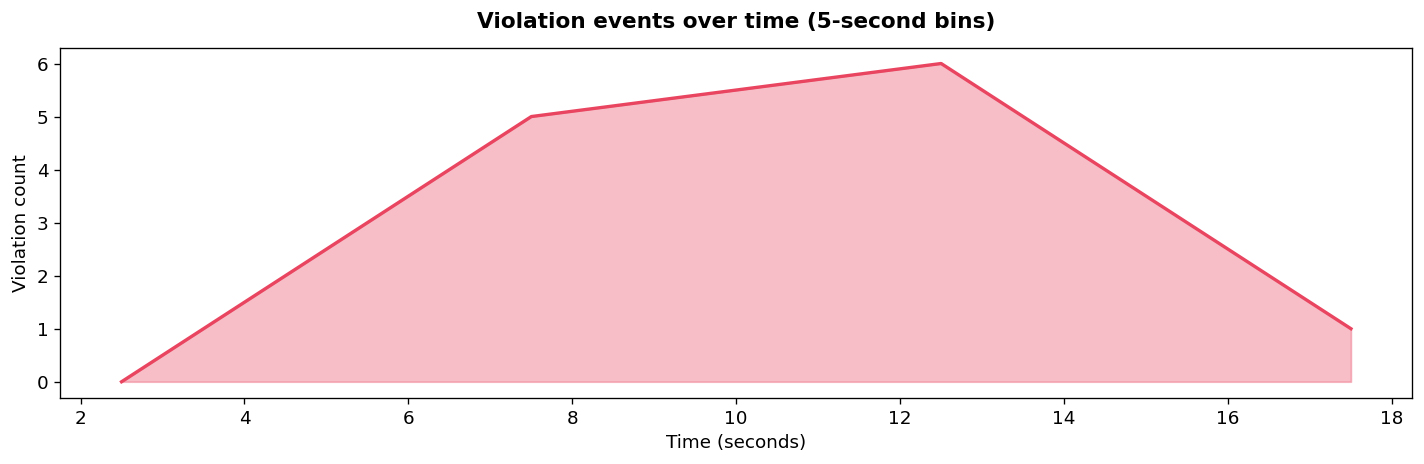

In [33]:
# Timeline (video only)
if "time_sec" in df_viols.columns and not df_viols.empty:
    bin_size = 5
    max_t    = int(df_viols["time_sec"].max()) + bin_size
    bins     = list(range(0, max_t, bin_size))
    counts_t, edges = np.histogram(df_viols["time_sec"], bins=bins)
    centers  = [(edges[i]+edges[i+1])/2 for i in range(len(edges)-1)]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.fill_between(centers, counts_t, alpha=0.35, color="#e94560")
    ax.plot(centers, counts_t, color="#e94560", linewidth=2)
    ax.set_title("Violation events over time (5-second bins)", fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Violation count")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "violations_timeline.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Timeline chart only available for video logs.")

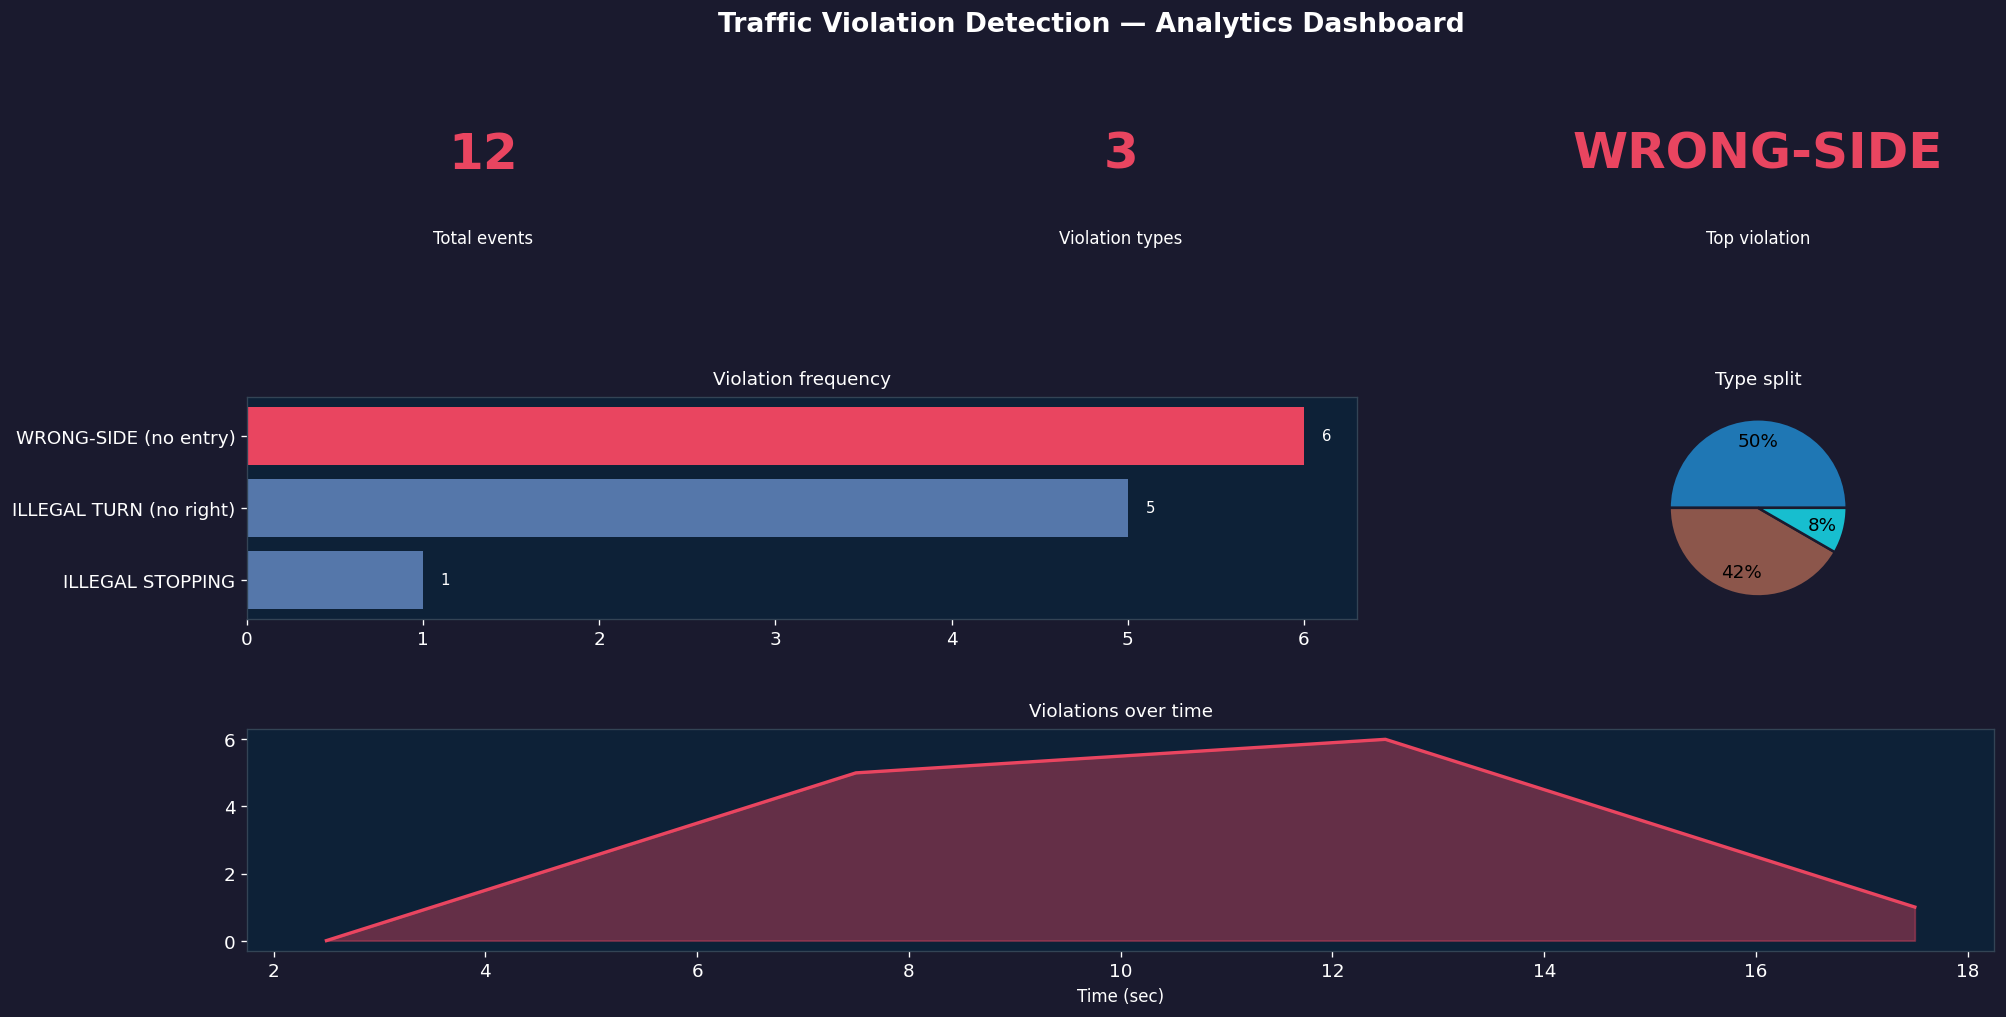

Saved → results/dashboard.png


In [34]:
# Full analytics dashboard
if not df_viols.empty and "violation" in df_viols.columns:
    counts = df_viols["violation"].value_counts()

    fig = plt.figure(figsize=(16, 9), facecolor="#1a1a2e")
    gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.35,
                             left=0.06, right=0.97, top=0.88, bottom=0.06)

    fig.suptitle("Traffic Violation Detection — Analytics Dashboard",
                 fontsize=16, fontweight="bold", color="white", y=0.93)

    # KPI cards
    kpis = [("Total events", len(df_viols)),
            ("Violation types", len(counts)),
            ("Top violation", counts.index[0].split()[0] if len(counts) else "—")]
    for i, (label, val) in enumerate(kpis):
        ax = fig.add_subplot(gs[0, i])
        ax.set_facecolor("#0f3460")
        ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
        ax.text(0.5, 0.60, str(val), ha="center", va="center",
                fontsize=30, fontweight="bold", color="#e94560")
        ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=10, color="white")

    # Bar chart
    ax_bar = fig.add_subplot(gs[1, :2])
    ax_bar.set_facecolor("#0d2137")
    colors = ["#e94560" if i==0 else "#5577aa" for i in range(len(counts))]
    ax_bar.barh(counts.index, counts.values, color=colors, edgecolor="none")
    for p, val in zip(ax_bar.patches, counts.values):
        ax_bar.text(val+0.1, p.get_y()+p.get_height()/2, str(val), va="center", fontsize=9, color="white")
    ax_bar.set_title("Violation frequency", color="white", fontsize=11, pad=8)
    ax_bar.tick_params(colors="white"); ax_bar.invert_yaxis()
    for s in ax_bar.spines.values(): s.set_color("#334455")

    # Pie chart
    ax_pie = fig.add_subplot(gs[1, 2])
    ax_pie.set_facecolor("#0d2137")
    pie_colors = plt.cm.tab10(np.linspace(0, 1, len(counts)))
    ax_pie.pie(counts.values, labels=None, autopct="%1.0f%%",
               colors=pie_colors, pctdistance=0.75,
               wedgeprops={"edgecolor": "#1a1a2e", "linewidth": 1.5})
    ax_pie.set_title("Type split", color="white", fontsize=11, pad=8)

    # Timeline
    ax_time = fig.add_subplot(gs[2, :])
    ax_time.set_facecolor("#0d2137")
    if "time_sec" in df_viols.columns:
        bin_size = 5
        max_t = int(df_viols["time_sec"].max()) + bin_size
        ct, edges = np.histogram(df_viols["time_sec"], bins=list(range(0,max_t,bin_size)))
        centers = [(edges[i]+edges[i+1])/2 for i in range(len(edges)-1)]
        ax_time.fill_between(centers, ct, alpha=0.4, color="#e94560")
        ax_time.plot(centers, ct, color="#e94560", linewidth=2)
        ax_time.set_xlabel("Time (sec)", color="white", fontsize=10)
    else:
        ax_time.text(0.5, 0.5, "No temporal data", ha="center", va="center",
                     color="#888", fontsize=12)
    ax_time.set_title("Violations over time", color="white", fontsize=11, pad=8)
    ax_time.tick_params(colors="white")
    for s in ax_time.spines.values(): s.set_color("#334455")

    plt.savefig(OUTPUT_DIR / "dashboard.png", dpi=150, bbox_inches="tight", facecolor="#1a1a2e")
    plt.show()
    print("Saved → results/dashboard.png")
else:
    print("No violation data to plot — run inference first.")

In [36]:
# Final summary
print("\n" + "═"*55)
print("  FINAL SUMMARY")
print("═"*55)
print(f"  Dataset    : {sum(train_counts.values()):,} train instances across 23 classes")
print(f"  Model      : {MODEL_SIZE}  (COCO pretrained → fine-tuned)")

try:
    print(f"  mAP@50     : {val_results.box.map50:.4f}")
    print(f"  mAP@50-95  : {val_results.box.map:.4f}")
except: print("  Metrics    : run Section 5 to populate")

print("\n  Output files:")
for f in sorted(OUTPUT_DIR.rglob("*")):
    if f.is_file(): print(f"    {f}")
print("═"*55)


═══════════════════════════════════════════════════════
  FINAL SUMMARY
═══════════════════════════════════════════════════════
  Dataset    : 5,872 train instances across 23 classes
  Model      : yolov8m  (COCO pretrained → fine-tuned)
  mAP@50     : 0.9275
  mAP@50-95  : 0.7967

  Output files:
    results/class_distribution.png
    results/dashboard.png
    results/inference_samples.png
    results/per_class_metrics.csv
    results/sample_grid_train.png
    results/traffic_video_annotated.mp4
    results/video_violation_log.json
    results/violation_frequency.png
    results/violation_metadata.json
    results/violations_timeline.png
═══════════════════════════════════════════════════════
